# Hierarchical binary inference across filters

> **Install:** this tutorial needs the `plots` extra (pandas and ChainConsumer): `pip install "virgil-astro[plots]"`.

When you have several datasets from different telescopes or wavelengths, you often want one scene geometry with a different flux in each, as in [SPARCO](https://arxiv.org/abs/1403.3343), where objects in the scene have their own SEDs.

Here we fit a binary to three interferometric observations at three wavelengths at once. The position is shared between filters, and each filter has its own flux ratio. The [Zodiax docs](https://louisdesdoigts.github.io/zodiax/optimisation_tools/) explore many of these ideas in more detail.

In [1]:
import logging
import warnings

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as onp
import numpyro
import numpyro.distributions as dist
import optimistix as optx
import pandas as pd
from jax.flatten_util import ravel_pytree
from numpyro.infer import MCMC, NUTS
from numpyro.infer.initialization import init_to_value

jax.config.update("jax_enable_x64", True)

warnings.filterwarnings("ignore", category=SyntaxWarning)  # upstream zodiax docstrings
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

from virgil.inference import (
    fisher_projection,
    expected_fisher,
    hessian_matrix,
    regularized_inverse,
)
from virgil.likelihood import (
    joint_data,
    joint_errors,
    joint_loglike,
    joint_prediction,
    posterior_predictive_summary,
)
from virgil.models import BinaryModelCartesian
from virgil.oidata import OIData
from virgil.plotting import (
    set_style,
    plot_chainconsumer_diagnostics,
    plot_data_model_correlation,
    plot_grid_map,
)

set_style()  # the figure style used throughout the docs

## Simulate three observations

The three `OIData` objects have the same baseline sampling and uncertainties, at wavelengths of 800 nm, 1.0 micron and 1.2 microns. The binary is about 22 mas from its primary, and 1.5, 1.0 and 0.7 per cent as bright in the three filters; the visibilities have an error of 3e-4 and the phases 0.04 degrees.

In [2]:
FILTER_LABELS = ("800 nm", "1.0 micron", "1.2 microns")
truth = {
    "dra": jnp.array(18.0),
    "ddec": jnp.array(-12.0),
    "log10_flux": jnp.log10(jnp.array([0.015, 0.010, 0.007])),
}

# Eighteen baselines of 1.5 to 6 m, all around the uv plane, shared by the filters.
angles = jnp.linspace(0.0, 2.0 * jnp.pi, 18, endpoint=False)
lengths = jnp.linspace(1.5, 6.0, angles.size)
u, v = lengths * jnp.cos(angles), lengths * jnp.sin(angles)

keys = jax.random.split(jax.random.key(7), len(FILTER_LABELS))
observations = tuple(
    OIData(
        {
            "u": u, "v": v, "wavel": jnp.array([wavelength]),
            "vis": jnp.ones_like(u), "d_vis": jnp.full_like(u, 3e-4),
            "phi": jnp.zeros_like(u), "d_phi": jnp.full_like(u, 0.04),
            "phi_unit": "deg", "v2_flag": False, "cp_flag": False,
        }
    ).with_model(
        BinaryModelCartesian(
            truth["dra"], truth["ddec"], 10.0 ** truth["log10_flux"][index]
        ),
        key=keys[index],
    )
    for index, wavelength in enumerate([800e-9, 1.0e-6, 1.2e-6])
)

{
    label: {
        "wavelength_um": round(float(observation.wavel[0]) * 1e6, 2),
        "n_baselines": int(observation.u.size),
        "flux_ratio": round(float(10.0 ** truth["log10_flux"][index]), 4),
    }
    for index, (label, observation) in enumerate(
        zip(FILTER_LABELS, observations)
    )
}


{'800 nm': {'wavelength_um': 0.8, 'n_baselines': 18, 'flux_ratio': 0.015},
 '1.0 micron': {'wavelength_um': 1.0, 'n_baselines': 18, 'flux_ratio': 0.01},
 '1.2 microns': {'wavelength_um': 1.2, 'n_baselines': 18, 'flux_ratio': 0.007}}

## Define the hierarchy

The hierarchy is an ordinary JAX pytree. The astrometry is shared, and indexing the flux vector picks out each observation's own flux. This is Zodiax's pattern: parameters stay separate from the objects that describe each observation.

In [3]:
params = {
    "dra": jnp.array(15.0),
    "ddec": jnp.array(-9.0),
    "log10_flux": jnp.log10(jnp.array([0.012, 0.012, 0.012])),
}


def binary_model(values, observation_index):
    return BinaryModelCartesian(values["dra"],values["ddec"],
                                10.0 ** values["log10_flux"][observation_index])


initial_loglike = joint_loglike(params, binary_model, observations)
truth_loglike = joint_loglike(truth, binary_model, observations)

print(f"log-likelihood at the starting guess: {float(initial_loglike):.1f}, at the simulation truth: {float(truth_loglike):.1f}")

log-likelihood at the starting guess: -5654.1, at the simulation truth: 682.3


## Joint grid initialization

Before fitting a separate flux in each filter, we search a compact grid in shared right ascension, declination and flux. The best shared-flux point gives a reliable starting position and the starting value of every filter's flux for the optimization and HMC.

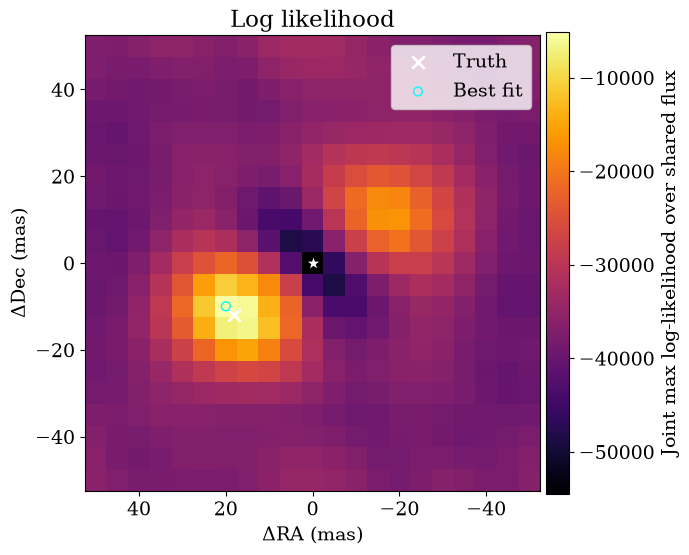

In [4]:
joint_grid_samples = {
    "dra": jnp.linspace(-50.0, 50.0, 21),
    "ddec": jnp.linspace(-50.0, 50.0, 21),
    "flux": 10.0 ** jnp.linspace(-4.0, -1.0, 16),
}
joint_grid_axes = jnp.meshgrid(*joint_grid_samples.values(), indexing="ij")
joint_grid_values = jnp.stack([axis.reshape(-1) for axis in joint_grid_axes], axis=1)

def shared_flux_loglike(values):
    shared_params = {
        "dra": values[0],
        "ddec": values[1],
        "log10_flux": jnp.full(
            len(observations), jnp.log10(values[2]), dtype=values.dtype)
            }
    return joint_loglike(shared_params, binary_model, observations)


joint_grid_loglike = jax.vmap(shared_flux_loglike)(joint_grid_values).reshape(
    tuple(axis.size for axis in joint_grid_samples.values()))
joint_grid_index = jnp.unravel_index(
    jnp.argmax(joint_grid_loglike), joint_grid_loglike.shape)
joint_grid_best = {
    name: float(joint_grid_samples[name][index])
    for name, index in zip(joint_grid_samples, joint_grid_index)}

plot_grid_map(
    joint_grid_loglike,
    joint_grid_samples,
    truth={"dra": float(truth["dra"]), "ddec": float(truth["ddec"])},
    best=joint_grid_best,
    label="Joint max log-likelihood over shared flux",
)

params = {
    "dra": jnp.array(joint_grid_best["dra"]),
    "ddec": jnp.array(joint_grid_best["ddec"]),
    "log10_flux": jnp.full(
        len(observations), jnp.log10(joint_grid_best["flux"])
    ),
}


## Preconditioning before Inference

The Fisher information matrix measures the information the data are expected to carry. It bounds the best covariance the data can give (the Cramér–Rao lower bound), and it normalizes parameters whose scales and correlations differ widely. Normalizing before inference preconditions the model for fast convergence.

In [5]:
prediction_fn = lambda values: joint_prediction(values, binary_model, observations)
errors = joint_errors(observations)
initial_fisher, unravel = expected_fisher(prediction_fn, params, errors, ridge=1e-8)
projection = fisher_projection(initial_fisher, eps=1e-10)

print(f"Fisher matrix: {initial_fisher.shape[0]} x {initial_fisher.shape[1]}")

Fisher matrix: 5 x 5


## Optimization

We optimize in the well-scaled local coordinates the Fisher matrix defines, then map the result back to the physical parameter tree.

In [6]:
initial_vector, unravel = ravel_pytree(params)


def project(latent):
    # project a latent vector back to the original space
    return unravel(initial_vector + projection @ latent)

def latent_objective(latent, args) :
    return -joint_loglike(project(latent), binary_model, observations)

solver = optx.BestSoFarMinimiser(optx.BFGS(rtol=1e-8, atol=1e-8))
solution = optx.minimise(
    latent_objective,
    solver,
    jnp.zeros_like(initial_vector),
    max_steps=256,
    throw=False,
)
recovered = project(solution.value)

initial_chi2r = jnp.sum(((joint_data(observations) - prediction_fn(params)) / errors) ** 2) / (
    errors.size - initial_vector.size
)
final_chi2r = jnp.sum(((joint_data(observations) - prediction_fn(recovered)) / errors) ** 2) / (
    errors.size - initial_vector.size
)
print(f"Reduced chi-squared: {float(initial_chi2r):.2f} -> {float(final_chi2r):.2f}")

Reduced chi-squared: 113.66 -> 0.89


In [7]:
recovered_vector, recovered_unravel = ravel_pytree(recovered)

def flat_objective(values):
    return -joint_loglike(recovered_unravel(values), binary_model, observations)


expected_info, _ = expected_fisher(prediction_fn, recovered, errors)
observed_info = hessian_matrix(flat_objective, recovered_vector)
laplace_covariance = regularized_inverse(observed_info, ridge=1e-8)
laplace_sigma = jnp.sqrt(jnp.diag(laplace_covariance))

parameter_names = ["ddec (mas)", "dra (mas)"] + [f"log10 flux ({label})" for label in FILTER_LABELS]
pd.DataFrame(
    {"estimate": onp.asarray(recovered_vector), "Laplace sigma": onp.asarray(laplace_sigma)},
    index=parameter_names,
)

,estimate,Laplace sigma
ddec (mas),-11.928194,0.048962
dra (mas),17.962123,0.048782
log10 flux (800 nm),-1.826236,0.001678
log10 flux (1.0 micron),-1.998476,0.002590
log10 flux (1.2 microns),-2.154878,0.004064


## Interpreting the local covariance

The table above comes from the Hessian of the negative log likelihood at the optimum: a local Laplace approximation, which we compare with HMC below.

## Hamiltonian Monte Carlo

NumPyro samples the same parameter tree, with a shared position and per-filter fluxes, starting from the joint grid maximum that the optimizer used.

In [8]:
def model_hmc():
    dra = numpyro.sample("dra", dist.Uniform(-30.0, 30.0)) # uniform prior in cartesian coordinates
    ddec = numpyro.sample("ddec", dist.Uniform(-30.0, 30.0))
    log10_flux = numpyro.sample(
        "log10_flux", dist.Uniform(-6.0, -1.0).expand([len(observations)])
    ) # uniform prior for the fluxes in log space, ie jeffreys prior
    values = {"dra": dra, "ddec": ddec, "log10_flux": log10_flux}
    numpyro.factor("loglike", joint_loglike(values, binary_model, observations))

init_values = {
    "dra": float(params["dra"]),
    "ddec": float(params["ddec"]),
    "log10_flux": params["log10_flux"],
}
# HMC with no U-turn sampler
kernel = NUTS(model_hmc, init_strategy=init_to_value(values=init_values)) 
mcmc = MCMC(
    kernel, num_warmup=800, num_samples=2000, num_chains=1, progress_bar=False
)
mcmc.run(jax.random.PRNGKey(2026))
posterior = mcmc.get_samples()

print(f"Posterior RA {jnp.median(posterior['dra']):.2f}, \
      Dec {jnp.median(posterior['ddec']):.2f}")
for index, name in enumerate(FILTER_LABELS):
    print(f"{name} Flux: {jnp.median(10.0 ** posterior['log10_flux'][:, index]):.4f}")

Posterior RA 17.96,       Dec -11.93
800 nm Flux: 0.0149
1.0 micron Flux: 0.0100
1.2 microns Flux: 0.0070


## Corner plot of shared and per-filter parameters

The recovered parameters against the values used to simulate the data:

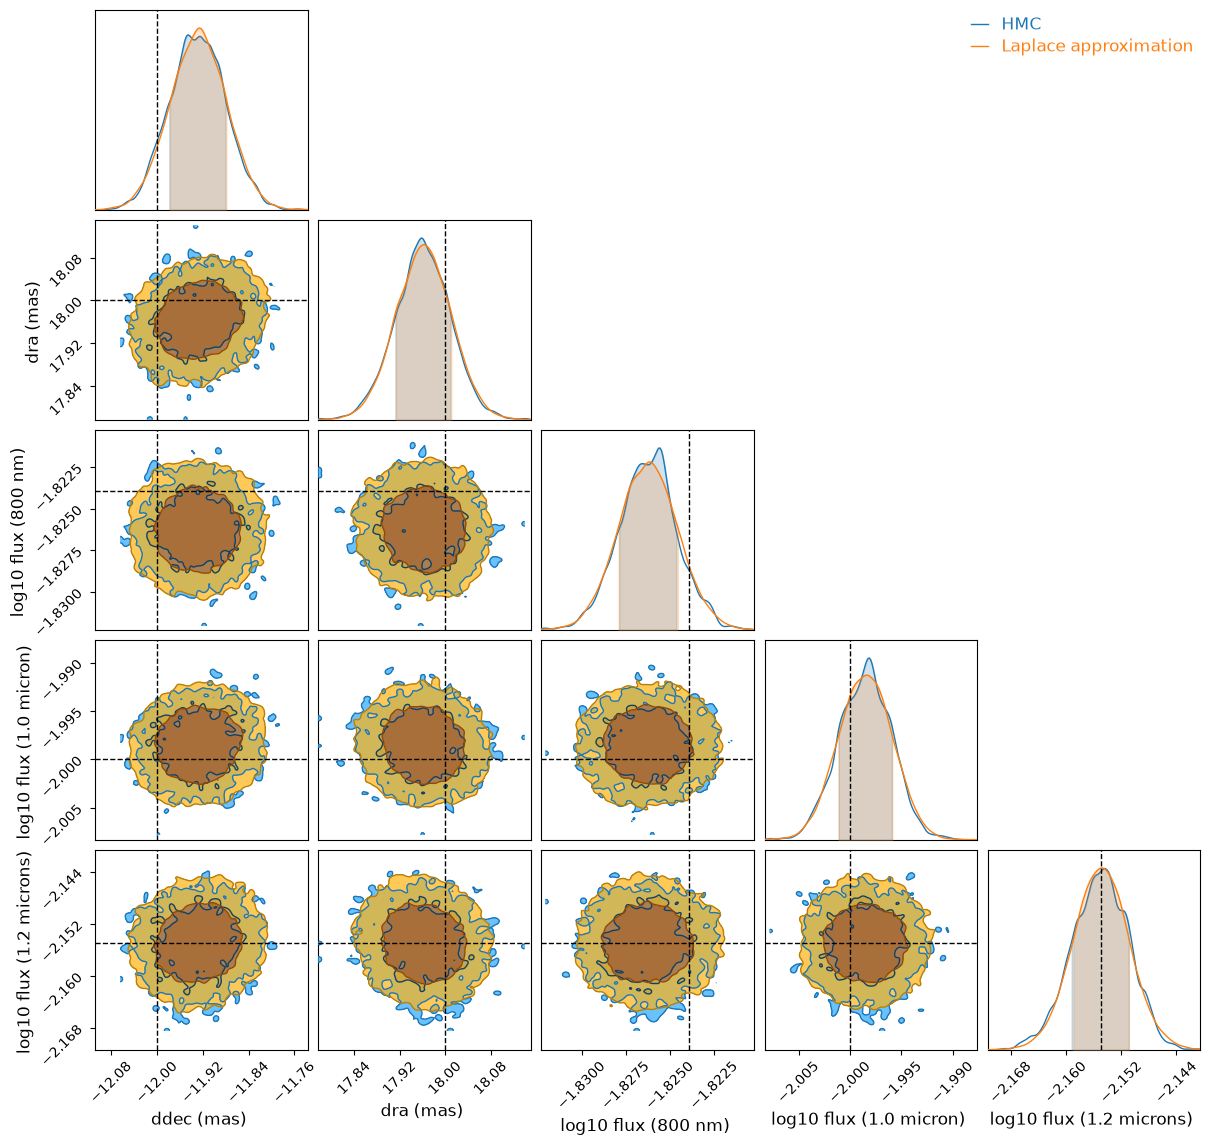

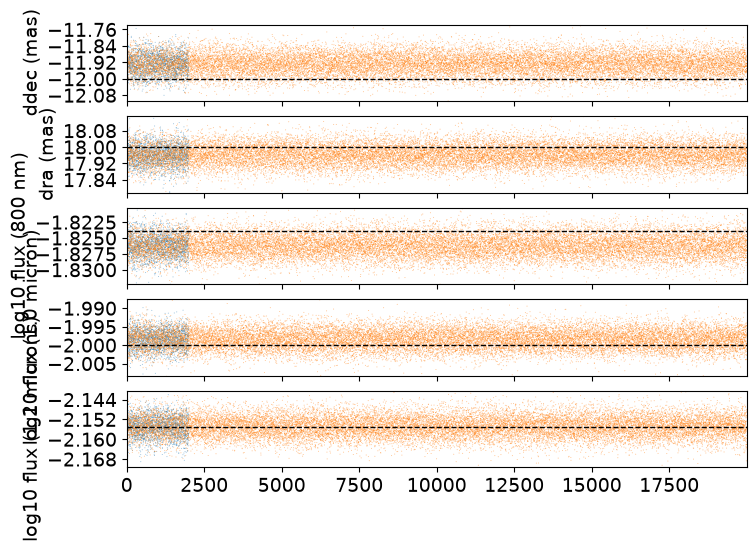

In [9]:
parameter_columns = ["ddec (mas)", "dra (mas)"] + [f"log10 flux ({label})" for label in FILTER_LABELS]

flat_recovered, unravel_recovered = ravel_pytree(recovered)
flat_truth, _ = ravel_pytree(truth)
n_samples = 20000
cholesky = jnp.linalg.cholesky(laplace_covariance)
standard_normal = jax.random.normal(jax.random.PRNGKey(11), (n_samples, flat_recovered.size))
latent_samples = flat_recovered[None, :] + standard_normal @ cholesky.T
laplace_samples_df = pd.DataFrame(onp.asarray(latent_samples), columns=parameter_columns)

hmc_samples_df = pd.DataFrame(
    {
        "ddec (mas)": onp.asarray(posterior["ddec"]),
        "dra (mas)": onp.asarray(posterior["dra"]),
        **{
            f"log10 flux ({label})": onp.asarray(posterior["log10_flux"][:, index])
            for index, label in enumerate(FILTER_LABELS)
        },
    }
)
truth_dict = dict(zip(parameter_columns, onp.asarray(flat_truth)))

plot_chainconsumer_diagnostics(
    {"HMC": hmc_samples_df, "Laplace approximation": laplace_samples_df},
    columns=parameter_columns,
    truth=truth_dict,
    colors=["#1f77b4", "#ff7f0e"],
);

## Posterior predictive correlation per filter

Check the fit against the data, not just the corner plot. Each filter has its own flux, so there is one data-vs-model correlation plot per observation, pairing the shared astrometry samples with that filter's flux samples.

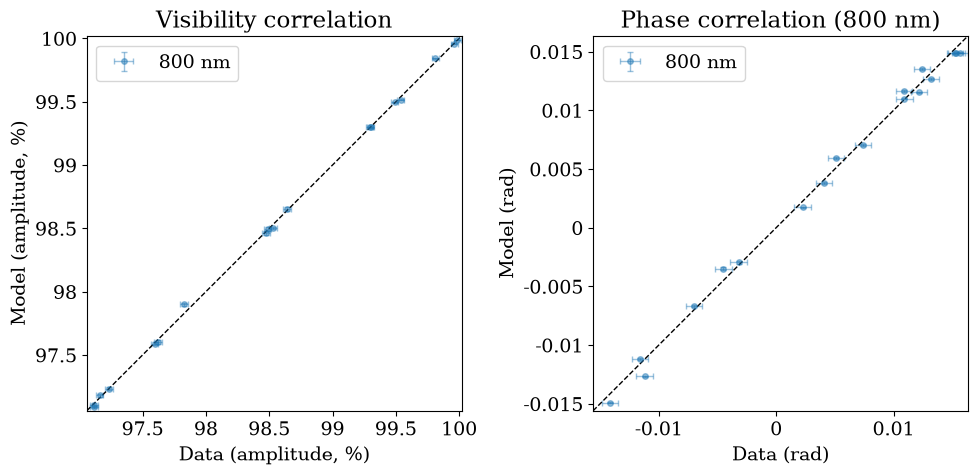

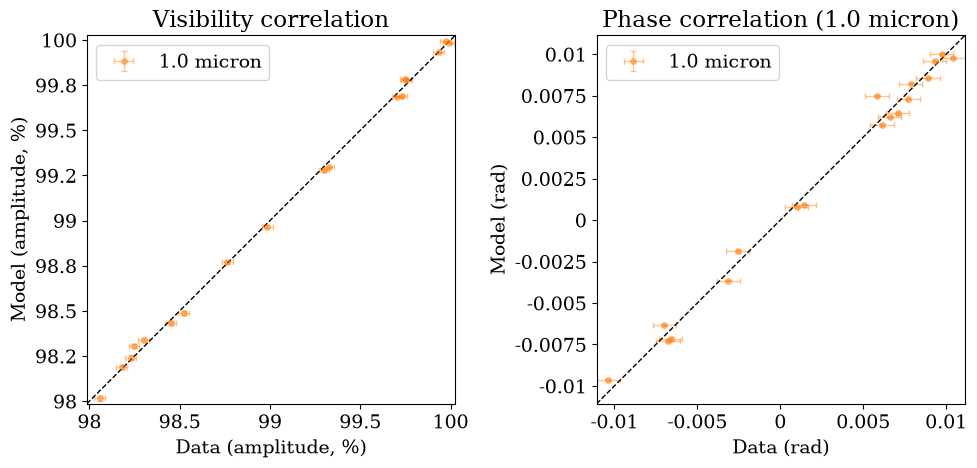

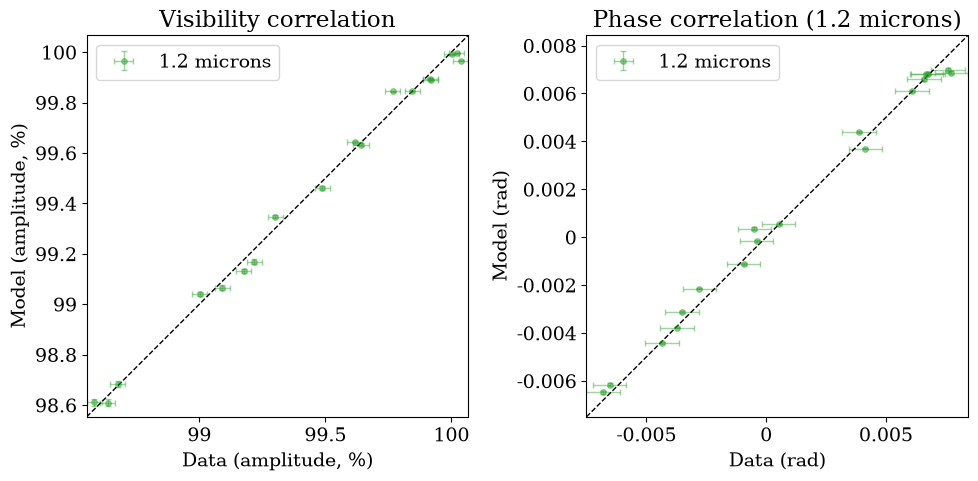

In [10]:
# Subsample the Laplace draws for the (slower, per-sample) posterior predictive check.
predictive_samples = jax.vmap(unravel_recovered)(latent_samples[:500])

for index, (label, observation) in enumerate(zip(FILTER_LABELS, observations)):
    filter_samples = {
        "dra": predictive_samples["dra"],
        "ddec": predictive_samples["ddec"],
        "flux": 10.0 ** predictive_samples["log10_flux"][:, index],
    }
    predicted = posterior_predictive_summary(
        filter_samples, BinaryModelCartesian, observation
    )
    plot_data_model_correlation(
        observation,
        {label: predicted},
        colors=[f"C{index}"],
        phase_title=f"Phase correlation ({label})",
    )
    plt.show()

## Visibility and phase versus baseline

Finally, visibility amplitude and phase against baseline length, one column per filter. The observations share the array geometry, so the baseline lengths are identical; only the flux, and so the fitted amplitude and phase, differs between filters.

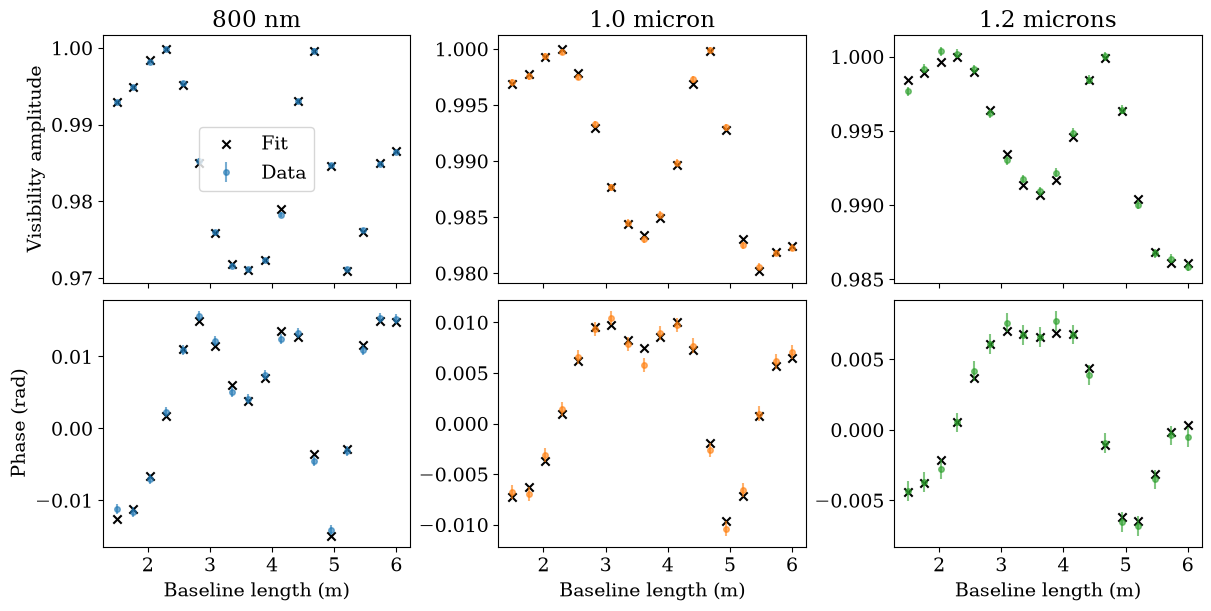

In [11]:
fig, axes = plt.subplots(
    2, 3, figsize=(12, 6), sharex=True, constrained_layout=True
)

for index, (label, observation) in enumerate(zip(FILTER_LABELS, observations)):
    baseline = jnp.sqrt(observation.u**2 + observation.v**2)
    cvis_fit = binary_model(recovered, index).model(
        observation.u, observation.v, observation.wavel
    )
    vis_fit = observation.to_vis(cvis_fit)
    phi_fit = observation.to_phases(cvis_fit)

    ax_vis, ax_phi = axes[0, index], axes[1, index]
    ax_vis.errorbar(
        baseline,
        observation.vis,
        yerr=observation.d_vis,
        fmt="o",
        markersize=4,
        alpha=0.6,
        color=f"C{index}",
        label="Data",
    )
    ax_vis.scatter(baseline, vis_fit, marker="x", color="k", label="Fit")
    ax_vis.set_title(label)

    ax_phi.errorbar(
        baseline,
        observation.phi,
        yerr=observation.d_phi,
        fmt="o",
        markersize=4,
        alpha=0.6,
        color=f"C{index}",
    )
    ax_phi.scatter(baseline, phi_fit, marker="x", color="k")
    ax_phi.set_xlabel("Baseline length (m)")

axes[0, 0].set_ylabel("Visibility amplitude")
axes[1, 0].set_ylabel("Phase (rad)")
axes[0, 0].legend(loc="best")
plt.show()